## 1. Setup - data loading - dataset overview

train_df: 4340 images, test_df: 1860 images
ground_truth
ai_generated    0.516129
authentic       0.483871
Name: proportion, dtype: float64


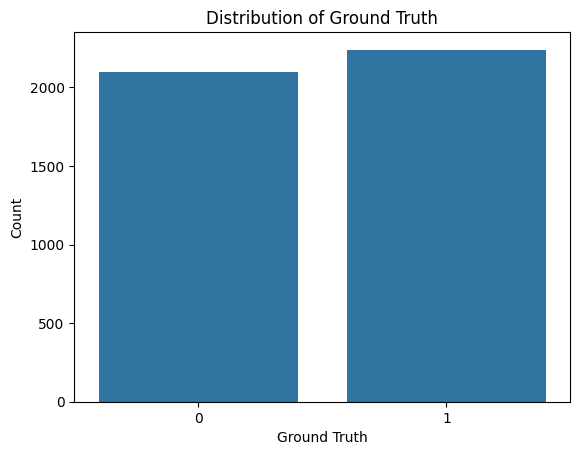

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image
from tqdm import tqdm
import cv2
import os

DATA_DIR = Path("./daniels_files/combined_notebook/data/google_drive/final_test_images/images_final_sample")

train_df = pd.read_csv(r"./daniels_files/combined_notebook/data/google_drive/train.csv")
test_df = pd.read_csv(r"./daniels_files/combined_notebook/data/google_drive/test.csv")

# Filter only available images
available_files = set(p.name for p in DATA_DIR.glob("*.jpg"))

train_df = train_df[train_df["image_id"].isin(available_files)].reset_index(drop=True)
test_df = test_df[test_df["image_id"].isin(available_files)].reset_index(drop=True)

# Dataset overview

print(f'train_df: {len(train_df)} images, test_df: {len(test_df)} images')

# train_df["ground_truth"].value_counts(normalize=True)
train_df["ground_truth"].value_counts(normalize=True).rename({0: "authentic", 1: "ai_generated"})
print(train_df["ground_truth"].value_counts(normalize=True).rename({0: "authentic", 1: "ai_generated"}))
# Plot the distribution of the target variable
sns.countplot(x='ground_truth', data=train_df)
plt.title('Distribution of Ground Truth')
plt.xlabel('Ground Truth')
plt.ylabel('Count')
plt.show()



We restricted analyis to the images available locally.
The train dataset is balanced.

## 2. Visual inspection

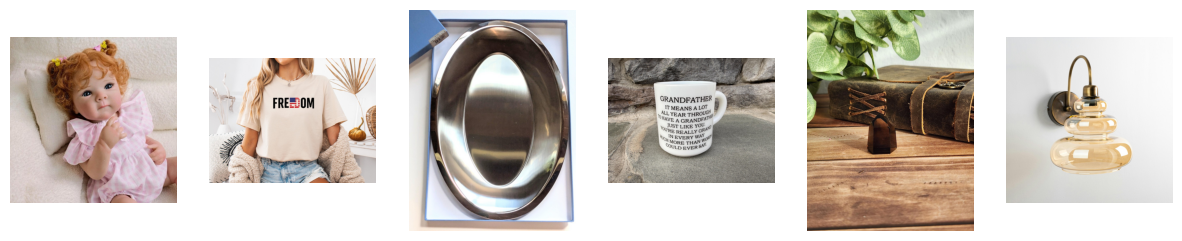

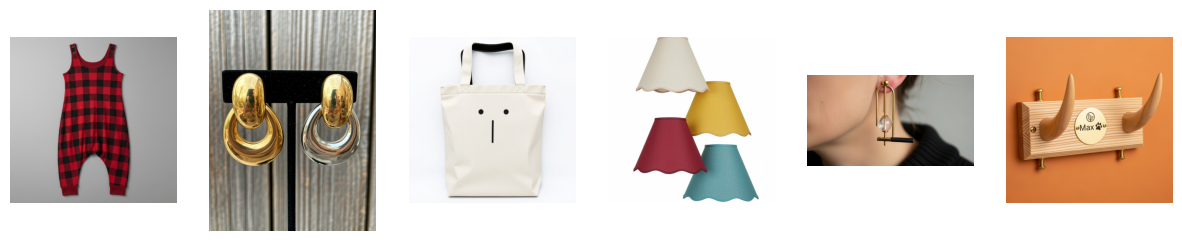

In [13]:
def show_samples(df, label, n=6):
    sample = df[df["ground_truth"] == label].sample(n)
    fig, axes = plt.subplots(1, n, figsize=(15, 3))
    
    for ax, (_, row) in zip(axes, sample.iterrows()):
        img = Image.open(DATA_DIR / row.image_id)
        ax.imshow(img)
        ax.axis("off")
    
    plt.show()

show_samples(train_df, 0)
show_samples(train_df, 1)

## 3. Image Size & Aspect Ratio

100%|██████████| 4340/4340 [00:00<00:00, 5249.14it/s]


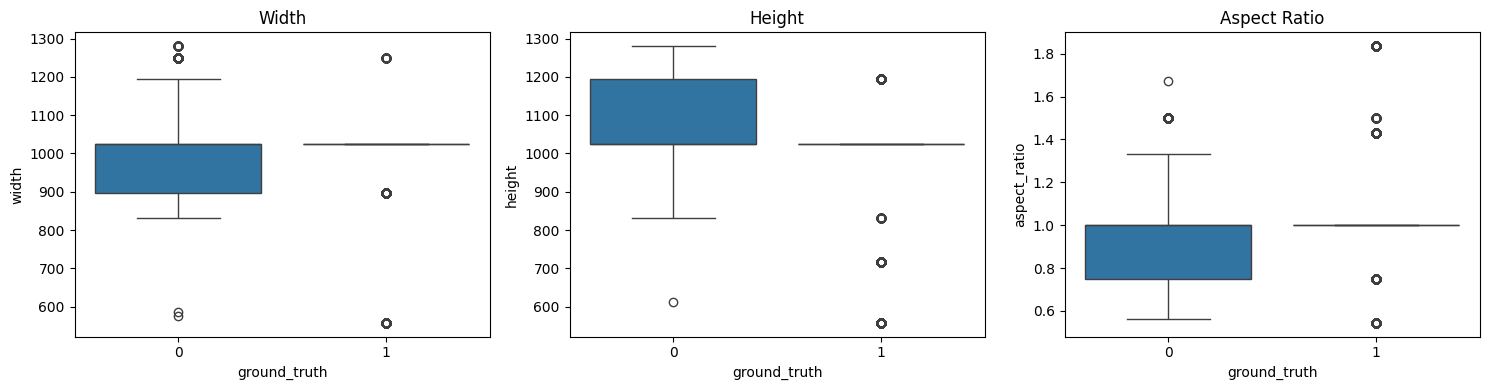

In [14]:
widths, heights = [], []

for img_id in tqdm(train_df["image_id"]):
    img = Image.open(DATA_DIR / img_id)
    w, h = img.size
    widths.append(w)
    heights.append(h)

train_df["width"] = widths
train_df["height"] = heights
train_df["aspect_ratio"] = train_df["width"] / train_df["height"]


# plots

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.boxplot(x="ground_truth", y="width", data=train_df, ax=axes[0])
axes[0].set_title("Width")

sns.boxplot(x="ground_truth", y="height", data=train_df, ax=axes[1])
axes[1].set_title("Height")

sns.boxplot(x="ground_truth", y="aspect_ratio", data=train_df, ax=axes[2])
axes[2].set_title("Aspect Ratio")

plt.tight_layout()
plt.show()

AI images: more uniform, closer to square

Real images: more diverse sizes

Maybe to be used as a feature, however not necessarly applicable on evaluation dataset.

## 4. Brightness & Colour Statistics

100%|██████████| 4340/4340 [00:28<00:00, 153.59it/s]


<Axes: xlabel='brightness', ylabel='Density'>

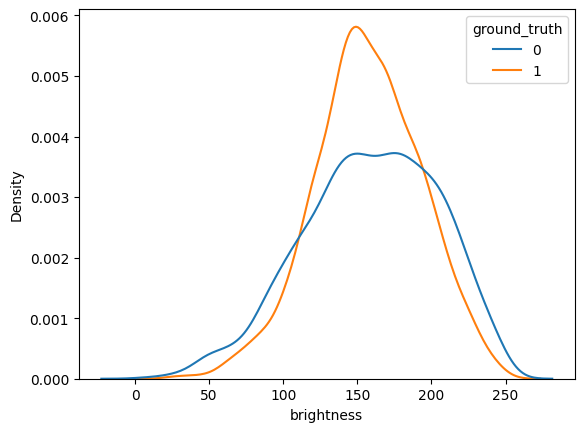

In [15]:
def mean_brightness(path):
    img = np.array(Image.open(path))
    return img.mean()

train_df["brightness"] = [
    mean_brightness(DATA_DIR / i)
    for i in tqdm(train_df["image_id"])
]


sns.kdeplot(data=train_df, x="brightness", hue="ground_truth")

- AI images are slightly darker (on average) 
- AI distribution  is tigher (less variance), so AI images are more consistent in brightness.
- Real images are more diverse.

One possible feature for modelling.



## 5. Sharpness

100%|██████████| 4340/4340 [00:42<00:00, 102.00it/s]


<Axes: xlabel='sharpness', ylabel='Density'>

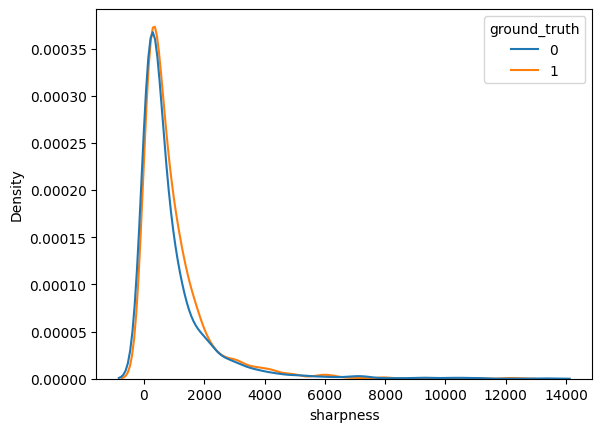

In [16]:
def sharpness(path):
    img = cv2.imread(str(path))
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return cv2.Laplacian(gray, cv2.CV_64F).var()

train_df["sharpness"] = [
    sharpness(DATA_DIR / i)
    for i in tqdm(train_df["image_id"])
]

# plot sharpness
sns.kdeplot(data=train_df, x="sharpness", hue="ground_truth")

Sharpness distributions are almost identical.

So it is not a feature that can separate classes.

6. FFT Energy

100%|██████████| 4340/4340 [03:10<00:00, 22.77it/s]


<Axes: xlabel='fft_energy', ylabel='Density'>

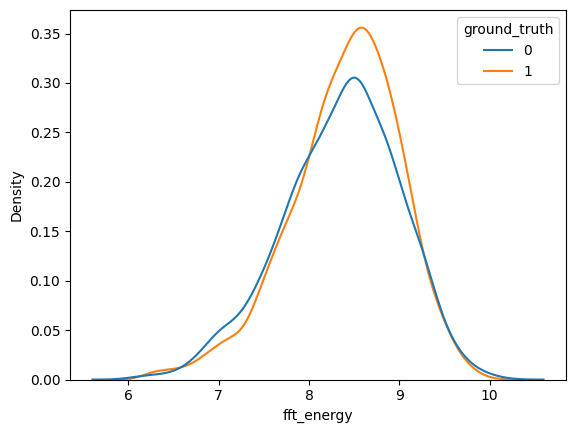

In [17]:
def fft_energy(path):
    img = np.array(Image.open(path).convert("L"))
    f = np.fft.fft2(img)
    return np.log(np.abs(f) + 1).mean()

train_df["fft_energy"] = [
    fft_energy(DATA_DIR / i)
    for i in tqdm(train_df["image_id"])
]


sns.kdeplot(data=train_df, x="fft_energy", hue="ground_truth")

AI images have slightly different frequency distribution, with a peak slightly higher.

## 7. File Size (Hidden Bias)

<Axes: xlabel='file_size', ylabel='Density'>

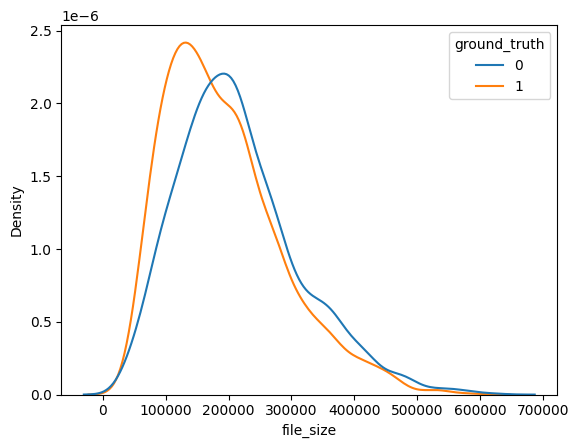

In [18]:
train_df["file_size"] = [
    os.path.getsize(DATA_DIR / i)
    for i in train_df["image_id"]
]

sns.kdeplot(data=train_df, x="file_size", hue="ground_truth")

AI images are slightly smaller
But could not generalise for test and validation datasets.

## 8. Feature Correlation

<Axes: >

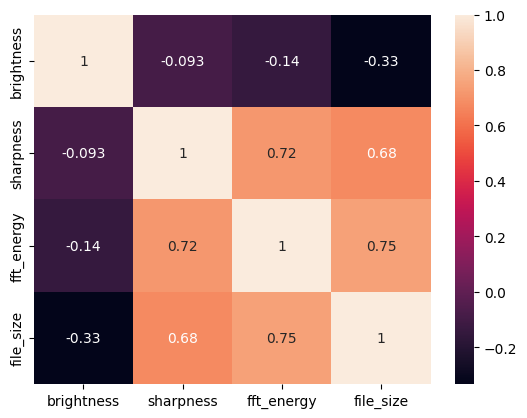

In [19]:
features = ["brightness", "sharpness", "fft_energy", "file_size"]

corr = train_df[features].corr()
sns.heatmap(corr, annot=True)

features strongly correlated:
- sharpness <~> fft_energy: 0.72
- fft_energy <~> file_size: 0.75
- sharpness <~> file_size: 0.68



## 9. Quick Baseline from EDA Features

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

X = train_df[features]
y = train_df["ground_truth"]

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

model = RandomForestClassifier()
model.fit(X_train, y_train)

preds = model.predict(X_val)

print("F1:", f1_score(y_val, preds))

F1: 0.6464646464646465
